In [1]:
#reload packages that have changed
%load_ext autoreload
%autoreload 2 

# Session 6 Notebook

## Functions

A **function** is a named, REUSABLE block of code that does a SPECIFIC job.
Instead of copy-pasting the same logic in multiple cells, you define it once and call it by name.

Key benefits:
- **Readability** — your notebook reads like a story, not a wall of code
- **Reusability** — call the same logic on different data files without rewriting it
- **Debuggability** — fix a bug once, in one place
- **Packagability** — functions are the building blocks of a proper Python package

In [2]:
def sum_prod(a,b,c=1) : # Here a and b are positional arguments, c is a key argument
    return c*(a+b)

In [3]:
sum_prod(1,2) # If you don't specify, c will always be equal to 1, key parameter

3

In [4]:
sum_prod(1,2,2) # Here we swapped it to 2, it matches to the position in the header essentially, don't change the order

6

In [5]:
name="Olivier"
age="newly qualified 1/4 life crisis"

In [6]:
print(name, age, sep= " is a ") # Example of keyword argument

Olivier is a newly qualified 1/4 life crisis


### Exercise 1st part

- Move data loader to a function called *read_pulse*

In [7]:
def read_pulse (fname) : 
    time = []
    absorption = []
    dataFile = open(fname) # Importing the file adding "../" Help go to the previous directory, solving our problem
    
    # Use a for loop to fill the lists
    
    dataFile.readline() # We don't want to read in the first since it's column headers, so we read through it once to get rid of it in essence
    
    for line in dataFile.readlines(): # Run a for loop through all rows of the file except row 0 
        line = line.split(",") # Split into two lists with the "," delimeter
        time.append(float(line[0])) # Add to the time list
        absorption.append(float(line[1])) # Add to the absorption list
    return time, absorption

In [10]:
time, absorption = read_pulse("../data/pulse_data.csv") # make sure to be in correct location before running, or move accordingly

## Packaging

 __version__ = "0.0.1"  
 
 - 1st number is a Major Change
 - 2nd is a minor change, such as a new feature
 - 3rd is an update, code just works better
 - 
https://semver.org/

## Exercise (Full version post-session)
Use functions to automate session4

### Load Data

In [12]:
import spacemed # key step here to make sure this all works when calling on the functions

In [13]:
spacemed.__version__

'0.0.1'

In [14]:
time, absorption = spacemed.read_pulse("../data/pulse_data.csv")

In [15]:
!pwd

/home/olso13/SpaceMed-2026/olso13/notebooks


In [16]:
import numpy # First  things first import your libraries
from matplotlib import pyplot as plt

## Algorithm Design

 Aim --> Find the heart rate using HR = 60/deltaTpeaks

Calculate the heart rate using a basic (w/o automatic functions). For loop that finds the global maximum of each cycle using a window!

In [18]:
%cd /home/olso13/SpaceMed-2026/olso13 # Change the working directory with console command so paths resolve correctly

[Errno 2] No such file or directory: '/home/olso13/SpaceMed-2026/olso13 # Change the working directory with console command so paths resolve correctly'
/home/olso13/SpaceMed-2026/olso13/notebooks


In [19]:
dataFile = open("/home/olso13/SpaceMed-2026/olso13/data/pulse_data.csv") # Open CSV file using path (not necessary but having it as reference is nice)

In [20]:
peaks = spacemed.find_peaks(absorption, w=150) #call on the function, add data file and define the sliding window (here 150 samples)

In [21]:
time = numpy.array(time) # Conversion to arrays
absorption = numpy.array(absorption)

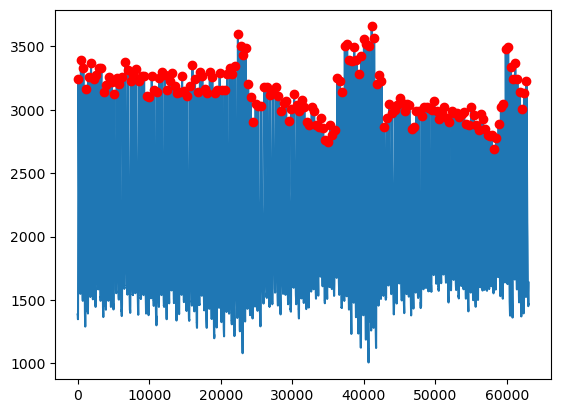

In [22]:
plt.plot(absorption)
plt.plot(peaks, absorption[peaks],"ro") # Okay this seems to all work now 

Now we can plot the heart rate using the time between the PPG peaks and the equation above! (inital aim aha !)

In [23]:
### Finding Heart Rata

In [24]:
hr = spacemed.calc_heart_rate(time, peaks) # Compute heart rate from findpeaks
# spacemed.calc_heart_rate uses the previous heart rate formula delta_time = tp[1:]-tp[:-1] & hr = 60/delta_t

Text(0, 0.5, 'Heart Rate (bpm)')

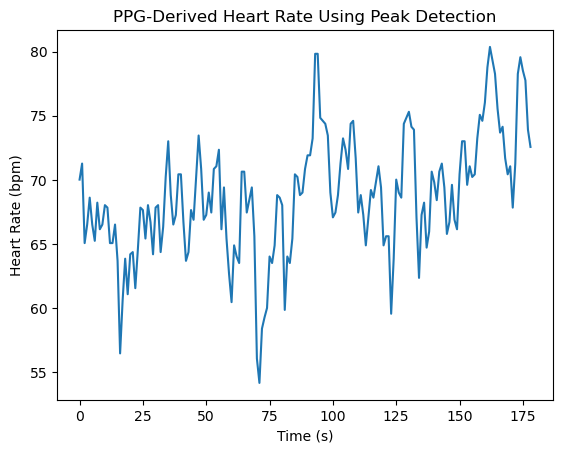

In [25]:
plt.plot(hr)
plt.title("PPG-Derived Heart Rate Using Peak Detection")
plt.xlabel("Time (s)")
plt.ylabel("Heart Rate (bpm)")

There we go, a nice labeled graph ! 